# MNIST Classification with MLP (2)

In [1]:
import copy
import torch
import torch.nn as nn
from torchvision import datasets
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 1. Load MNIST

In [2]:
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True
)

# Randomly split the training dataset into training and validation sets
torch.manual_seed(0)
indices = torch.randperm(len(train_dataset))

train_indices = indices[:20000]
val_indices = indices[20000:25000]

X_train = train_dataset.data[train_indices].float() / 255.0
y_train = train_dataset.targets[train_indices]

X_val = train_dataset.data[val_indices].float() / 255.0
y_val = train_dataset.targets[val_indices]

# Use the official MNIST test set only for final evaluation
X_test = test_dataset.data.float() / 255.0
y_test = test_dataset.targets

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:  ", X_val.shape)
print("y_val:  ", y_val.shape)
print("X_test: ", X_test.shape)
print("y_test: ", y_test.shape)

X_train: torch.Size([20000, 28, 28])
y_train: torch.Size([20000])
X_val:   torch.Size([5000, 28, 28])
y_val:   torch.Size([5000])
X_test:  torch.Size([10000, 28, 28])
y_test:  torch.Size([10000])


## 2. Define MLP

In [3]:
class MyMlp(nn.Module):
    def __init__(self):
        super().__init__()

        # Fully-connected (fc) layers
        self.W1 = nn.Linear(784, 128)
        self.W2 = nn.Linear(128, 64)
        self.W3 = nn.Linear(64, 10)

        # ReLU activation function
        self.relu = nn.ReLU()

    def forward(self, x):
        z1 = self.W1(x)
        h1 = self.relu(z1)

        z2 = self.W2(h1)
        h2 = self.relu(z2)

        y = self.W3(h2)

        return y

model = MyMlp().to(device)
print(model)

MyMlp(
  (W1): Linear(in_features=784, out_features=128, bias=True)
  (W2): Linear(in_features=128, out_features=64, bias=True)
  (W3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)


## 3. Train

In [4]:
# CrossEntropyLoss internally applies Softmax
loss_function = nn.CrossEntropyLoss()

# Optimizer with weight decay (L2 regularization)
optimizer = torch.optim.SGD(
    model.parameters(), lr = 0.01, weight_decay=1e-4
)

# Training settings
num_epochs = 30
batch_size = 64

# Move data to selected device (CPU or GPU)
X_train = X_train.to(device)
y_train = y_train.to(device)
X_val = X_val.to(device)
y_val = y_val.to(device)

best_model_val_acc = 0.0
best_epoch = 0
best_model = None

for epoch in range(num_epochs):

    # Set the model to training mode
    model.train()

    total_loss = 0

    # Divide the data into mini-batches
    for start in range(0, len(X_train), batch_size):

        end = start + batch_size

        # Get one mini-batch
        images = X_train[start:end]
        labels = y_train[start:end]

        # Flatten: [batch, 28, 28] -> [batch, 784]
        images = images.reshape(images.size(0), 28 * 28)

        # Forwarding
        outputs = model(images)

        # Compute loss
        loss = loss_function(outputs, labels)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    # Average training loss
    avg_loss = total_loss / ((len(X_train) + batch_size - 1) // batch_size)

    # Evaluate on the validation set
    model.eval()

    with torch.no_grad():
        X_val_flat = X_val.reshape(len(X_val), 28 * 28)
        val_outputs = model(X_val_flat)
        val_predictions = val_outputs.argmax(dim=1)

        val_accuracy = 100 * (val_predictions == y_val).float().mean().item()

    # Save the model with the highest validation accuracy
    if val_accuracy > best_model_val_acc:
        best_model_val_acc = val_accuracy
        best_epoch = epoch + 1
        best_model = copy.deepcopy(model)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {avg_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/30] Loss: 2.2558 | Val Accuracy: 42.08%
Epoch [2/30] Loss: 1.9014 | Val Accuracy: 71.72%
Epoch [3/30] Loss: 1.1221 | Val Accuracy: 79.72%
Epoch [4/30] Loss: 0.7250 | Val Accuracy: 83.22%
Epoch [5/30] Loss: 0.5737 | Val Accuracy: 85.56%
Epoch [6/30] Loss: 0.4916 | Val Accuracy: 87.28%
Epoch [7/30] Loss: 0.4396 | Val Accuracy: 88.30%
Epoch [8/30] Loss: 0.4041 | Val Accuracy: 88.94%
Epoch [9/30] Loss: 0.3784 | Val Accuracy: 89.44%
Epoch [10/30] Loss: 0.3587 | Val Accuracy: 89.84%
Epoch [11/30] Loss: 0.3429 | Val Accuracy: 90.12%
Epoch [12/30] Loss: 0.3295 | Val Accuracy: 90.24%
Epoch [13/30] Loss: 0.3179 | Val Accuracy: 90.36%
Epoch [14/30] Loss: 0.3074 | Val Accuracy: 90.70%
Epoch [15/30] Loss: 0.2979 | Val Accuracy: 90.90%
Epoch [16/30] Loss: 0.2891 | Val Accuracy: 91.04%
Epoch [17/30] Loss: 0.2809 | Val Accuracy: 91.24%
Epoch [18/30] Loss: 0.2731 | Val Accuracy: 91.42%
Epoch [19/30] Loss: 0.2657 | Val Accuracy: 91.50%
Epoch [20/30] Loss: 0.2587 | Val Accuracy: 91.74%
Epoch [21

## 4. Evaluate Best Model

In [5]:
# Use the model with the highest validation accuracy
best_model.eval()

# Move the test set to selected device (CPU or GPU)
X_test = X_test.to(device)
y_test = y_test.to(device)

# Evaluate the selected model on the test set
with torch.no_grad():
    X_test_flat = X_test.reshape(len(X_test), 28 * 28)
    test_outputs = best_model(X_test_flat)
    test_predictions = test_outputs.argmax(dim=1)

    test_accuracy = 100 * (test_predictions == y_test).float().mean().item()

print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Accuracy: {best_model_val_acc:.2f}%")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Best Epoch: 30
Best Validation Accuracy: 92.84%
Test Accuracy: 93.92%


## 5. Check Learned Model

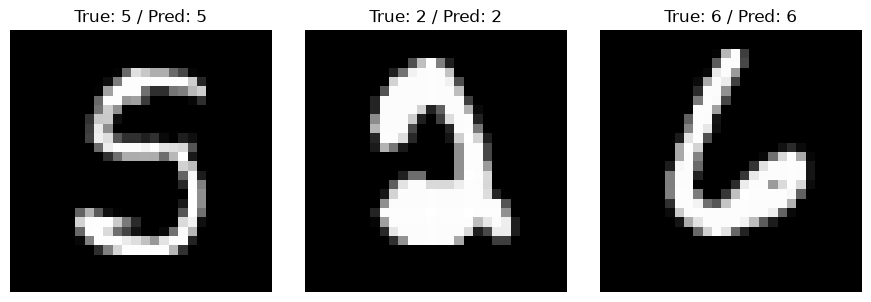

In [6]:
# Randomly select 3 test images
indices = torch.randperm(len(X_test), device=device)[:3]

X_check = X_test[indices]
y_check = y_test[indices]

# Set the model to evaluation mode
best_model.eval()

# Disable gradient calculation
with torch.no_grad():
    X_check_flat = X_check.reshape(3, 28 * 28)
    outputs = best_model(X_check_flat)
    predictions = outputs.argmax(dim=1)

# Show 3 images
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for i in range(3):
    axes[i].imshow(X_check[i].cpu(), cmap="gray")
    axes[i].set_title(f"True: {y_check[i].item()} / Pred: {predictions[i].item()}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()